In [1]:
# ============================================================
# Tablas_por_enlace (celda de Jupyter) — v1.9
# Tablas por enlace (como la Table A1 del paper), para ω = 0:
#   Link | CV% | PeakRatio | P99 | ARIMA | Naive | Arch1 | Arch2 | Arch3 | Arch4
#   - Una tabla por métrica (MAE, RMSE, MAPE, WAPE), horizonte (5, 15) y modo (A, B).
#   - En negrita el mejor modelo de cada enlace y de la fila GLOBAL.
#   - Mismos instantes para todos los modelos, Realidad > TRIGGER.
#   - GLOBAL: media de los enlaces (MAE, RMSE, MAPE); para WAPE, Σ|error| / Σ real.
# Se muestran en el notebook. Con GUARDAR_TEX = True también se guardan en Tablas_latex/.
# ============================================================
import os
import numpy as np
import pandas as pd
from IPython.display import display, HTML

ROOT_RESULTS = "Results_min_Base"
DIR_BASE     = "Results_min_Base/results_baselines_1min"
CARPETA      = "results_Arq{ID}_{H}m_{MODO}_W60_w00_H{H}"
COL_PRED     = "Prediccion"            # ω = 0
IDS          = [1, 2, 3, 4]
TRIGGER      = 1000
HORIZONTES   = [5, 15]
MODOS        = ["A", "B"]
METRICAS     = ["MAE", "RMSE", "MAPE", "WAPE"]
DIR_SALIDA   = "Tablas_latex"
GUARDAR_TEX  = True
DIR_CHRONOS  = "results_chronos-bolt-small_C60_{H}m"      # dentro de ROOT_RESULTS
MODOS_MASCARA = ["A", "B"]     # arquitecturas que fijan los instantes comunes, aunque MODOS solo tenga "A"
HACER_POR_ENLACE = True
HACER_RESUMEN    = True
FUENTE_OMEGA     = "movil60"      # pred (modelo horario) | movil60 | hora_ant | real (con fuga, solo cota)
OMEGAS_RESUMEN   = [0]


def sci(v):
    """9.45e+01 → 9.45e1 (formato de la Table A1)."""
    if pd.isna(v):
        return "--"
    m, e = f"{v:.2e}".split("e")
    return f"{m}e{int(e)}"


def _red(x, dec):
    """Redondeo .5 hacia arriba con 'dec' decimales."""
    from decimal import Decimal, ROUND_HALF_UP
    q = Decimal(1).scaleb(-dec)
    return Decimal(repr(float(x))).quantize(q, rounding=ROUND_HALF_UP)


def val(v):
    """Formato de los valores de ARIMA, Naive y Arch."""
    if pd.isna(v):
        return "--"
    if v > 9999:
        e = int(np.floor(np.log10(v)))
        m = _red(v / 10 ** e, 1)
        if m >= 10:
            m, e = _red(m / 10, 1), e + 1
        return f"{m}e{e}"
    if v >= 999:
        return str(int(_red(v, 0)))
    return f"{_red(v, 1)}"


def leer(ID, H, MODO):
    d = os.path.join(ROOT_RESULTS, CARPETA.format(ID=ID, H=H, MODO=MODO))
    if not os.path.isdir(d):
        print(f"⚠️ falta {d}")
        return {}
    pref = "test_" + os.path.basename(d).removeprefix("results_") + "_"
    return {f[len(pref):-4]: pd.read_csv(os.path.join(d, f), parse_dates=["timestamp"])
                                .set_index("timestamp")[["Realidad", COL_PRED]]
            for f in os.listdir(d) if f.startswith(pref) and f.endswith(".csv")}


def leer_chronos(H):
    """{enlace: ruta CSV} de Chronos para el horizonte H."""
    d = os.path.join(ROOT_RESULTS, DIR_CHRONOS.format(H=H))
    if not os.path.isdir(d):
        raise SystemExit(f"❌ No existe {d} (ejecuta Test_Chronos.py)")
    pref = "test_" + os.path.basename(d).removeprefix("results_") + "_"
    return {f[len(pref):-4]: os.path.join(d, f) for f in os.listdir(d)
            if f.startswith(pref) and f.endswith(".csv")}


def col_chronos(ruta):
    return (pd.read_csv(ruta, parse_dates=["timestamp"]).set_index("timestamp")[["Prediccion"]]
              .rename(columns={"Prediccion": "Chronos"}))


_CACHE = {}


def instantes(H, e):
    """Instantes comunes fijos para (H, enlace): Realidad > TRIGGER y predicción ω = 0 de todas las
    arquitecturas de MODOS_MASCARA, ARIMA y Chronos. No depende de MODOS."""
    if (H, e) in _CACHE:
        return _CACHE[(H, e)]
    idx = None
    for ID in IDS:
        for M in MODOS_MASCARA:
            n = CARPETA.format(ID=ID, H=H, MODO=M)
            f = os.path.join(ROOT_RESULTS, n, f"test_{n.removeprefix('results_')}_{e}.csv")
            if not os.path.exists(f):
                continue
            t = pd.read_csv(f, parse_dates=["timestamp"]).set_index("timestamp")[["Realidad", COL_PRED]].dropna()
            t = t[t["Realidad"] > TRIGGER]
            idx = t.index if idx is None else idx.intersection(t.index)
    fb = os.path.join(DIR_BASE, f"test_results_{e}_baselines.csv")
    fc = leer_chronos(H).get(e)
    if idx is None or not os.path.exists(fb) or fc is None:
        _CACHE[(H, e)] = None
        return None
    b = pd.read_csv(fb, parse_dates=["timestamp"]).set_index("timestamp")[f"ARIMA_t+{H}"].dropna()
    c = col_chronos(fc)["Chronos"].dropna()
    idx = idx.intersection(b.index).intersection(c.index)
    _CACHE[(H, e)] = idx
    return idx


def caracterizar(enlace):
    """CV%, PeakRatio y P99 del tráfico real (Realidad > TRIGGER), como en el comparador."""
    f = os.path.join(DIR_BASE, f"test_results_{enlace}_baselines.csv")
    v = pd.to_numeric(pd.read_csv(f)["Realidad"], errors="coerce").dropna()
    v = v[v > TRIGGER]
    if v.empty or v.mean() <= 0:
        return np.nan, np.nan, np.nan
    return v.std() / v.mean() * 100, v.max() / v.mean(), np.percentile(v, 99)


def tabla_metricas(H, MODO):
    """DataFrame por enlace con las 4 métricas de cada modelo + caracterización."""
    arqs = {ID: a for ID in IDS if (a := leer(ID, H, MODO))}
    if not arqs:
        return None, None, None
    modelos = ["ARIMA", "Chronos"] + [f"Arch{ID}" for ID in arqs]
    filas, suma_err, suma_y = [], {m: 0.0 for m in modelos}, 0.0
    chr_ = leer_chronos(H)

    for e in sorted(set.intersection(*[set(a) for a in arqs.values()], set(chr_))):
        fb = os.path.join(DIR_BASE, f"test_results_{e}_baselines.csv")
        if not os.path.exists(fb):
            continue
        j = None
        for ID, a in arqs.items():
            col = a[e].rename(columns={COL_PRED: f"Arch{ID}"})
            j = col if j is None else j.join(col[[f"Arch{ID}"]], how="inner")
        b = pd.read_csv(fb, parse_dates=["timestamp"]).set_index("timestamp")
        j = j.join(b[[f"ARIMA_t+{H}"]].rename(columns={f"ARIMA_t+{H}": "ARIMA"}), how="inner")
        j = j.join(col_chronos(chr_[e]), how="inner")
        idx = instantes(H, e)
        if idx is None:
            continue
        j = j.reindex(idx)
        if j.isna().any().any():
            print(f"⚠️ {e} T+{H} {MODO}: NaN dentro de los instantes comunes"); j = j.dropna()
        if j.empty:
            continue
        y = j["Realidad"].values
        cv, pr, p99 = caracterizar(e)
        fila = {"Link": e, "CV%": cv, "PeakRatio": pr, "P99": p99}
        suma_y += y.sum()
        for m in modelos:
            err = y - j[m].values
            fila[("MAE", m)]  = np.abs(err).mean()
            fila[("RMSE", m)] = np.sqrt((err ** 2).mean())
            fila[("MAPE", m)] = np.mean(np.abs(err) / y) * 100
            fila[("WAPE", m)] = np.abs(err).sum() / y.sum() * 100
            suma_err[m] += np.abs(err).sum()
        filas.append(fila)

    df = pd.DataFrame(filas)
    globales = {met: {m: df[(met, m)].mean() for m in modelos} for met in ["MAE", "RMSE", "MAPE"]}
    globales["WAPE"] = {m: 100 * suma_err[m] / suma_y for m in modelos}
    return df, modelos, globales


def latex(df, modelos, globales, metrica, H, MODO):
    esc = lambda s: s.replace("_", r"\_")
    cab = ["Link", r"CV\%", "PeakRatio", "P99"] + [esc(m if m in ("ARIMA", "Chronos") else f"{m}_{MODO}")
                                                   for m in modelos]
    lineas = [r"\begin{table}[p]", r"\centering", r"\scriptsize",
              r"\begin{tabular}{l" + "r" * (len(cab) - 1) + "}", r"\toprule",
              " & ".join(rf"\textbf{{{c}}}" for c in cab) + r" \\", r"\midrule"]
    for _, r in df.iterrows():
        vals = {m: r[(metrica, m)] for m in modelos}
        mejor = min(vals, key=vals.get)
        celdas = [esc(r["Link"]), f"{r['CV%']:.1f}", f"{r['PeakRatio']:.1f}", sci(r["P99"])]
        celdas += [rf"\textbf{{{val(vals[m])}}}" if m == mejor else val(vals[m]) for m in modelos]
        lineas.append(" & ".join(celdas) + r" \\")
    g = globales[metrica]
    mejor = min(g, key=g.get)
    lineas += [r"\midrule",
               " & ".join([r"\textbf{GLOBAL}", "", "", ""] +
                          [rf"\textbf{{{val(g[m])}}}" if m == mejor else val(g[m]) for m in modelos]) + r" \\",
               r"\botrule", r"\end{tabular}"]
    nota = " (GLOBAL: $\\sum|e|/\\sum y$ over all links)" if metrica == "WAPE" else ""
    unidad = " (\\%)" if metrica in ("MAPE", "WAPE") else ""
    lineas += [rf"\caption{{{metrica}{unidad} per link for $t+{H}$ min, $W=60$, $\omega=0.00$, "
               rf"variant {MODO}, and ground truth $> 1{{,}}000${nota}. Chronos: Chronos-Bolt (small), zero-shot, "
               rf"60-min context. Best model per link in bold.}}",
               rf"\label{{tab:{metrica.lower()}_h{H}_{MODO}}}", r"\end{table}"]
    return "\n".join(lineas)


def neg(texto, mejor):
    return f"<b>{texto}</b>" if mejor else texto


def mostrar(tabla):
    display(HTML(tabla.to_html(escape=False)))


def tabla_notebook(df, modelos, globales, metrica, MODO):
    nombres = {m: (m if m in ("ARIMA", "Chronos") else f"{m}_{MODO}") for m in modelos}
    filas = []
    for _, r in df.iterrows():
        vals = {m: r[(metrica, m)] for m in modelos}
        mejor = min(vals, key=vals.get)
        fila = {"Link": r["Link"], "CV%": f"{r['CV%']:.1f}", "PeakRatio": f"{r['PeakRatio']:.1f}",
                "P99": sci(r["P99"])}
        fila.update({nombres[m]: neg(val(vals[m]), m == mejor) for m in modelos})
        filas.append(fila)
    g = globales[metrica]
    mejor = min(g, key=g.get)
    filas.append({"Link": "GLOBAL", "CV%": "", "PeakRatio": "", "P99": "",
                  **{nombres[m]: neg(val(g[m]), m == mejor) for m in modelos}})
    return pd.DataFrame(filas).set_index("Link")


# ------------------------------------------------------------
# TABLA RESUMEN (Table 3): métrica media sobre los enlaces
# ------------------------------------------------------------
def col_omega(w):
    return "Prediccion" if w == 0 else f"Pred_{FUENTE_OMEGA}_w{w:02d}"


def resumen(H):
    """{(ω, modelo): {métrica: valor}} para un horizonte. Mismos instantes para todos."""
    datos = {}                                   # (ID, MODO) -> {enlace: df}
    for ID in IDS:
        for MODO in MODOS:
            d = os.path.join(ROOT_RESULTS, CARPETA.format(ID=ID, H=H, MODO=MODO))
            if not os.path.isdir(d):
                print(f"⚠️ falta {d}"); continue
            pref = "test_" + os.path.basename(d).removeprefix("results_") + "_"
            datos[(ID, MODO)] = {f[len(pref):-4]: os.path.join(d, f) for f in os.listdir(d)
                                 if f.startswith(pref) and f.endswith(".csv")}
    if not datos:
        return None
    cols = [col_omega(w) for w in OMEGAS_RESUMEN]
    modelos = [f"Arch{ID}_{MODO}" for (ID, MODO) in datos]
    chr_ = leer_chronos(H)
    acum = {}                                    # (ω, modelo) -> {MAE:[], RMSE:[], MAPE:[], se, sy}
    for e in sorted(set.intersection(*[set(v) for v in datos.values()], set(chr_))):
        fb = os.path.join(DIR_BASE, f"test_results_{e}_baselines.csv")
        if not os.path.exists(fb):
            continue
        j = None
        for (ID, MODO), fich in datos.items():
            t = pd.read_csv(fich[e], parse_dates=["timestamp"]).set_index("timestamp")
            falta = [c for c in cols if c not in t.columns]
            if falta:
                print(f"❌ {fich[e]} no tiene {falta}"); return None
            t = t[["Realidad"] + cols].rename(columns={c: (w, f"Arch{ID}_{MODO}")
                                                       for c, w in zip(cols, OMEGAS_RESUMEN)})
            j = t if j is None else j.join(t.drop(columns="Realidad"), how="inner")
        b = pd.read_csv(fb, parse_dates=["timestamp"]).set_index("timestamp")
        j = j.join(b[[f"ARIMA_t+{H}"]].rename(columns={f"ARIMA_t+{H}": "ARIMA"}), how="inner")
        j = j.join(col_chronos(chr_[e]), how="inner")
        idx = instantes(H, e)
        if idx is None:
            continue
        j = j.reindex(idx)
        if j.empty:
            continue
        for w in OMEGAS_RESUMEN:
            for m in ["ARIMA", "Chronos"] + modelos:
                p = j[m] if m in ("ARIMA", "Chronos") else j[(w, m)]
                ok = p.notna().values
                if not ok.all():
                    print(f"⚠️ {e} T+{H} ω={w}% {m}: {int((~ok).sum())} NaN de {len(ok)} instantes (se quitan solo para él)")
                y = j["Realidad"].values[ok]
                err = y - p.values[ok]
                a = acum.setdefault((w, m), {"MAE": [], "RMSE": [], "MAPE": [], "se": 0.0, "sy": 0.0})
                a["MAE"].append(np.abs(err).mean())
                a["RMSE"].append(np.sqrt((err ** 2).mean()))
                a["MAPE"].append(np.mean(np.abs(err) / y) * 100)
                a["se"] += np.abs(err).sum(); a["sy"] += y.sum()
    n_enl = len(next(iter(acum.values()))["MAE"]) if acum else 0
    res = {k: {"MAE": np.mean(a["MAE"]), "RMSE": np.mean(a["RMSE"]), "MAPE": np.mean(a["MAPE"]),
               "WAPE": 100 * a["se"] / a["sy"]} for k, a in acum.items()}
    return res, modelos, n_enl


def resumen_latex(R, metrica, n_enl):
    archs = sorted({m.split("_")[0] for m in R[HORIZONTES[0]][1]})
    cab1 = [r"\textbf{H}", r"$\boldsymbol{\omega}$", r"\textbf{ARIMA}", r"\textbf{Chronos}"] + \
           [rf"\multicolumn{{2}}{{c}}{{\textbf{{{a}}}}}" for a in archs]
    cmid = " ".join(rf"\cmidrule(lr){{{5 + 2 * i}-{6 + 2 * i}}}" for i in range(len(archs)))
    cab2 = ["", "", "", ""] + [r"\textbf{A}", r"\textbf{B}"] * len(archs)
    L = [r"\begin{table}[t]", r"\centering", r"\footnotesize",
         r"\begin{tabular}{ll" + "r" * (2 + 2 * len(archs)) + "}", r"\toprule",
         " & ".join(cab1) + r" \\", cmid, " & ".join(cab2) + r" \\", r"\midrule"]
    for k, H in enumerate(HORIZONTES):
        res, modelos, _ = R[H]
        orden = ["ARIMA", "Chronos"] + [f"{a}_{md}" for a in archs for md in ("A", "B")]
        for i, w in enumerate(OMEGAS_RESUMEN):
            vals = {m: res[(w, m)][metrica] for m in orden if (w, m) in res}
            mejor = min(vals, key=vals.get)
            celdas = [rf"\multirow{{{len(OMEGAS_RESUMEN)}}}{{*}}{{T+{H}}}" if i == 0 else "", f"{w}\\%"]
            celdas += [(rf"\textbf{{{val(vals[m])}}}" if m == mejor else val(vals[m])) if m in vals else "--"
                       for m in orden]
            L.append(" & ".join(celdas) + r" \\")
        if k < len(HORIZONTES) - 1:
            L.append(r"\midrule")
    unidad = " (\\%)" if metrica in ("MAPE", "WAPE") else ""
    media = "pooled over" if metrica == "WAPE" else "averaged over"
    fuente = {"pred": "the hourly forecast", "movil60": "the mean of the last 60 observed minutes",
              "hora_ant": "the mean of the last complete hour",
              "real": "the true hourly mean (oracle, upper bound)"}[FUENTE_OMEGA]
    cap = [rf"\caption{{Mean {metrica}{unidad} {media} all {n_enl} links at minute-level granularity, for each "
           rf"prediction horizon $H$, combination weight $\omega$ with {fuente}, architecture, and target "
           rf"formulation. Variant A: logarithmic difference; Variant B: logarithmic value. Chronos: Chronos-Bolt (small), "
           rf"zero-shot, with a 60-min context. Best value per row in bold.}}",
           rf"\label{{tab:resumen_{metrica.lower()}_{FUENTE_OMEGA}}}"]
    L = L[:2] + cap + L[2:] + [r"\botrule", r"\end{tabular}", r"\end{table}"]   # caption arriba, como la Table 3
    return "\n".join(L)


def resumen_notebook(R, metrica):
    filas = []
    for H in HORIZONTES:
        res, modelos, _ = R[H]
        orden = ["ARIMA", "Chronos"] + sorted(modelos)
        for w in OMEGAS_RESUMEN:
            vals = {m: res[(w, m)][metrica] for m in orden if (w, m) in res}
            mejor = min(vals, key=vals.get)
            filas.append({"H": f"T+{H}", "ω": f"{w}%",
                          **{m: neg(val(v), m == mejor) for m, v in vals.items()}})
    return pd.DataFrame(filas).set_index(["H", "ω"])


pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 250)
if GUARDAR_TEX:
    os.makedirs(DIR_SALIDA, exist_ok=True)

if HACER_POR_ENLACE:
    for H in HORIZONTES:
        for MODO in MODOS:
            df, modelos, globales = tabla_metricas(H, MODO)
            if df is None:
                continue
            for metrica in METRICAS:
                print(f"\n===== {metrica} per link — t+{H} min · W=60 · ω=0.00 · variante {MODO} · real > {TRIGGER} "
                      f"· {len(df)} enlaces  (negrita = mejor) =====")
                mostrar(tabla_notebook(df, modelos, globales, metrica, MODO))
                if GUARDAR_TEX:
                    with open(os.path.join(DIR_SALIDA, f"tabla_{metrica}_H{H}_{MODO}.tex"), "w") as f:
                        f.write(latex(df, modelos, globales, metrica, H, MODO) + "\n")

if HACER_RESUMEN:
    R = {}
    for H in HORIZONTES:
        r = resumen(H)
        if r is not None:
            R[H] = r
    if len(R) == len(HORIZONTES):
        n_enl = R[HORIZONTES[0]][2]
        for metrica in METRICAS:
            print(f"\n===== RESUMEN {metrica} — media sobre {n_enl} enlaces · ω con '{FUENTE_OMEGA}' (negrita = mejor de la fila) =====")
            mostrar(resumen_notebook(R, metrica))
            if GUARDAR_TEX:
                with open(os.path.join(DIR_SALIDA, f"resumen_{metrica}_{FUENTE_OMEGA}.tex"), "w") as f:
                    f.write(resumen_latex(R, metrica, n_enl) + "\n")


===== MAE per link — t+5 min · W=60 · ω=0.00 · variante A · real > 1000 · 81 enlaces  (negrita = mejor) =====


,CV%,PeakRatio,P99,ARIMA,Chronos,Arch1_A,Arch2_A,Arch3_A,Arch4_A
Link,,,,,,,,,
ADH_ADH,111.7,10.4,2.01e7,2.2e6,2.2e6,2.2e6,2.3e6,2.3e6,2.4e6
ADH_CVK,112.2,8.1,5.13e5,4.0e4,4.0e4,4.2e4,4.5e4,4.1e4,4.3e4
ADH_HTW,88.0,5.0,1.63e7,1.4e6,1.4e6,1.7e6,2.7e6,2.5e6,1.6e6
ADH_HU,100.4,8.8,5.84e5,4.8e4,4.9e4,4.6e4,5.0e4,4.7e4,4.6e4
ADH_SPK,131.3,14.2,1.32e6,8.8e4,8.0e4,7.8e4,8.4e4,7.9e4,9.8e4
ADH_TU,87.7,6.0,8.10e5,8.0e4,7.7e4,7.8e4,8.5e4,1.0e5,8.2e4
ADH_UP,95.3,12.2,1.07e5,8782,8457,8460,9269,8639,8578
ADH_WIAS,243.4,70.7,7.68e5,7.7e4,6.1e4,6.0e4,6.3e4,5.8e4,6.1e4
ADH_ZIB,85.8,9.9,1.33e6,1.3e5,1.2e5,1.3e5,1.3e5,1.2e5,1.3e5



===== RMSE per link — t+5 min · W=60 · ω=0.00 · variante A · real > 1000 · 81 enlaces  (negrita = mejor) =====


,CV%,PeakRatio,P99,ARIMA,Chronos,Arch1_A,Arch2_A,Arch3_A,Arch4_A
Link,,,,,,,,,
ADH_ADH,111.7,10.4,2.01e7,4.2e6,4.5e6,4.1e6,4.1e6,4.1e6,4.1e6
ADH_CVK,112.2,8.1,5.13e5,6.6e4,6.6e4,7.0e4,7.4e4,6.8e4,7.2e4
ADH_HTW,88.0,5.0,1.63e7,2.6e6,2.6e6,3.0e6,4.1e6,3.7e6,3.0e6
ADH_HU,100.4,8.8,5.84e5,8.3e4,8.5e4,7.9e4,8.3e4,8.3e4,8.1e4
ADH_SPK,131.3,14.2,1.32e6,2.3e5,2.0e5,1.9e5,1.9e5,1.9e5,2.1e5
ADH_TU,87.7,6.0,8.10e5,1.3e5,1.2e5,1.2e5,1.3e5,1.7e5,1.3e5
ADH_UP,95.3,12.2,1.07e5,1.9e4,1.8e4,1.8e4,1.9e4,1.8e4,1.8e4
ADH_WIAS,243.4,70.7,7.68e5,3.2e5,2.8e5,2.8e5,2.8e5,2.8e5,2.8e5
ADH_ZIB,85.8,9.9,1.33e6,2.2e5,2.1e5,2.2e5,2.2e5,2.1e5,2.2e5



===== MAPE per link — t+5 min · W=60 · ω=0.00 · variante A · real > 1000 · 81 enlaces  (negrita = mejor) =====


...

,,ARIMA,Chronos,Arch1_A,Arch1_B,Arch2_A,Arch2_B,Arch3_A,Arch3_B,Arch4_A,Arch4_B
H,ω,,,,,,,,,,
T+5,0%,1.3e6,1.2e6,1.2e6,1.6e6,1.3e6,1.7e6,1.3e6,1.7e6,1.3e6,1.6e6
T+15,0%,1.5e6,1.5e6,1.4e6,1.9e6,1.5e6,1.9e6,1.5e6,1.9e6,1.5e6,1.9e6



===== RESUMEN MAPE — media sobre 81 enlaces · ω con 'movil60' (negrita = mejor de la fila) =====


,,ARIMA,Chronos,Arch1_A,Arch1_B,Arch2_A,Arch2_B,Arch3_A,Arch3_B,Arch4_A,Arch4_B
H,ω,,,,,,,,,,
T+5,0%,161.5,133.6,95.1,212.6,109.7,386.1,109.8,331.6,111.2,135.3
T+15,0%,233.3,206.3,149.5,309.4,163.4,230.1,151.9,243.6,177.6,225.4



===== RESUMEN WAPE — media sobre 81 enlaces · ω con 'movil60' (negrita = mejor de la fila) =====


,,ARIMA,Chronos,Arch1_A,Arch1_B,Arch2_A,Arch2_B,Arch3_A,Arch3_B,Arch4_A,Arch4_B
H,ω,,,,,,,,,,
T+5,0%,37.1,35.8,36.3,58.1,38.2,63.5,39.0,59.8,39.0,56.8
T+15,0%,45.7,44.2,44.4,71.0,47.1,68.6,46.3,72.6,49.3,71.9


In [4]:
# ============================================================
# Comparar_1v1_Chronos_Base.py — v1.7
# ============================================================
import os
import numpy as np
import pandas as pd

# ============================================================
# CONFIGURACIÓN (igual que Tablas_por_enlace v1.9)
# ============================================================
ROOT_RESULTS  = "Results_min_Base"
DIR_BASE      = "Results_min_Base/results_baselines_1min"
CARPETA       = "results_Arq{ID}_{H}m_{MODO}_W60_w00_H{H}"
DIR_CHRONOS   = "results_chronos-bolt-small_C60_{H}m"     # dentro de ROOT_RESULTS
COL_PRED      = "Prediccion"                              # ω = 0
IDS           = [1, 2, 3, 4]
MODOS         = ["A", "B"]          # modelos que salen en las tablas
MODOS_MASCARA = ["A", "B"]          # modelos que fijan los instantes comunes (como en v1.9)
TRIGGER       = 1000
HORIZONTES    = [5, 15]
METRICA       = "WAPE"              # WAPE | MAPE | MAE
REFERENCIAS   = ["ARIMA", "Chronos"]
# ============================================================


def metrica_enlace(y, p):
    err = np.abs(y - p)
    if METRICA == "WAPE":
        return err.sum() / y.sum() * 100
    if METRICA == "MAE":
        return err.mean()
    return np.mean(err / y) * 100                        # MAPE (y > TRIGGER, nunca 0)


def es_enlace_valido(enlace):
    partes = enlace.split("_")
    return len(partes) == 2 and all(len(p) >= 2 for p in partes)


def enlaces_chronos(H):
    d = os.path.join(ROOT_RESULTS, DIR_CHRONOS.format(H=H))
    if not os.path.isdir(d):
        raise SystemExit(f"❌ No existe {d} (ejecuta Test_Chronos.py)")
    pref = "test_" + os.path.basename(d).removeprefix("results_") + "_"
    return {f[len(pref):-4]: os.path.join(d, f) for f in sorted(os.listdir(d))
            if f.startswith(pref) and f.endswith(".csv") and es_enlace_valido(f[len(pref):-4])}


def cargar_enlace(H, e, ruta_chronos):
    """Realidad + predicción ω = 0 de todos los modelos, en los instantes comunes del enlace."""
    j = None
    for ID in IDS:
        for M in MODOS_MASCARA:
            n = CARPETA.format(ID=ID, H=H, MODO=M)
            f = os.path.join(ROOT_RESULTS, n, f"test_{n.removeprefix('results_')}_{e}.csv")
            if not os.path.exists(f):
                continue
            t = (pd.read_csv(f, parse_dates=["timestamp"]).set_index("timestamp")[["Realidad", COL_PRED]]
                   .rename(columns={COL_PRED: f"Arq{ID}_{M}"}))
            j = t if j is None else j.join(t.drop(columns="Realidad"), how="inner")
    fb = os.path.join(DIR_BASE, f"test_results_{e}_baselines.csv")
    if j is None or not os.path.exists(fb):
        return None
    b = (pd.read_csv(fb, parse_dates=["timestamp"]).set_index("timestamp")[[f"ARIMA_t+{H}"]]
           .rename(columns={f"ARIMA_t+{H}": "ARIMA"}))
    c = (pd.read_csv(ruta_chronos, parse_dates=["timestamp"]).set_index("timestamp")[["Prediccion"]]
           .rename(columns={"Prediccion": "Chronos"}))
    j = j.join(b, how="inner").join(c, how="inner").dropna()
    j = j[j["Realidad"] > TRIGGER]
    return j if len(j) else None


def caracterizar(e):
    """CV%, PeakRatio y P99 del tráfico real del test (Realidad > TRIGGER), como en el apéndice."""
    f = os.path.join(DIR_BASE, f"test_results_{e}_baselines.csv")
    v = pd.to_numeric(pd.read_csv(f)["Realidad"], errors="coerce").dropna()
    v = v[v > TRIGGER]
    if v.empty or v.mean() <= 0:
        return {"CV%": np.nan, "PicoRatio": np.nan, "P99": np.nan}
    return {"CV%": v.std() / v.mean() * 100, "PicoRatio": v.max() / v.mean(), "P99": np.percentile(v, 99)}


def stats_de_enlaces(enlaces, stats):
    sub = pd.DataFrame([stats[e] for e in enlaces]) if enlaces else pd.DataFrame()
    res = {}
    for col in ["CV%", "PicoRatio", "P99"]:
        res[f"{col}_mean"] = round(sub[col].mean(), 2) if len(sub) else None
        res[f"{col}_med"]  = round(sub[col].median(), 2) if len(sub) else None
    return res


def fmt_stat(v):
    return "N/A" if v is None else str(v)


def comparar():
    filas = []
    for H in HORIZONTES:
        chr_ = enlaces_chronos(H)
        met = {}                      # modelo -> {enlace: métrica}
        se, sy = {}, {}               # para el WAPE GLOBAL de control
        stats = {}
        for e, ruta in chr_.items():
            j = cargar_enlace(H, e, ruta)
            if j is None:
                continue
            y = j["Realidad"].values
            for m in [c for c in j.columns if c != "Realidad"]:
                p = j[m].values
                met.setdefault(m, {})[e] = metrica_enlace(y, p)
                se[m] = se.get(m, 0.0) + np.abs(y - p).sum()
                sy[m] = sy.get(m, 0.0) + y.sum()
            stats[e] = caracterizar(e)

        print(f"\n✅ T+{H}: {len(stats)} enlaces en instantes comunes")
        print("   WAPE GLOBAL (Σ|e|/Σy) — debe coincidir con la Tabla 4 / fila GLOBAL del apéndice:")
        print("   " + " | ".join(f"{m} {100 * se[m] / sy[m]:.1f}" for m in sorted(se)))

        modelos = [f"Arq{ID}_{M}" for ID in IDS for M in MODOS if f"Arq{ID}_{M}" in met]
        for r in REFERENCIAS:
            ref = met.get(r, {})
            print(f"\n{'#'*70}")
            print(f"  T+{H} min | W=60 | ω=0 | criterio {METRICA} | vs {r} | instantes comunes")
            print(f"{'#'*70}")
            print(f"{'Modelo':>16}  {'Gana':>5}  {'Pierde':>6}  {'Total':>6}  {'%Win':>6}  "
                  f"{'CV%_G':>7}  {'Pico_G':>7}  {'P99_G':>12}  "
                  f"{'CV%_P':>7}  {'Pico_P':>7}  {'P99_P':>12}")
            print("-" * 110)
            for mod in modelos:
                comunes = sorted(set(met[mod]) & set(ref))
                if not comunes:
                    continue
                gana   = [e for e in comunes if met[mod][e] < ref[e]]
                pierde = [e for e in comunes if met[mod][e] > ref[e]]
                empata = [e for e in comunes if met[mod][e] == ref[e]]
                total  = len(comunes)
                pct    = round(100 * len(gana) / total, 1)
                sg, sp = stats_de_enlaces(gana, stats), stats_de_enlaces(pierde, stats)
                print(f"{mod:>16}  {len(gana):>5}  {len(pierde):>6}  {total:>6}  {pct:>5.1f}%  "
                      f"{fmt_stat(sg['CV%_mean']):>7}  {fmt_stat(sg['PicoRatio_mean']):>7}  "
                      f"{fmt_stat(sg['P99_mean']):>12}  "
                      f"{fmt_stat(sp['CV%_mean']):>7}  {fmt_stat(sp['PicoRatio_mean']):>7}  "
                      f"{fmt_stat(sp['P99_mean']):>12}")
                filas.append({
                    "H": H, "Modelo": mod, "Referencia": r,
                    "N_total": total, "N_gana": len(gana), "N_pierde": len(pierde), "N_empata": len(empata),
                    "Pct_win": pct,
                    **{f"Gana_{k}": v for k, v in sg.items()},
                    **{f"Pierde_{k}": v for k, v in sp.items()},
                    "enlaces_gana": "|".join(gana), "enlaces_pierde": "|".join(pierde),
                })

    df_out = pd.DataFrame(filas)
    if not df_out.empty:
        salida = os.path.join(ROOT_RESULTS, f"1v1_vs_ARIMA_Chronos_{METRICA}.csv")
        df_out.to_csv(salida, index=False)
        print(f"\n💾 CSV guardado: {salida}")
        print("\n" + "=" * 60 + "\n  RESUMEN: % de enlaces ganados\n" + "=" * 60)
        print(df_out.pivot_table(index="Modelo", columns=["H", "Referencia"], values="Pct_win").to_string())


if __name__ == "__main__":
    comparar()


✅ T+5: 81 enlaces en instantes comunes
   WAPE GLOBAL (Σ|e|/Σy) — debe coincidir con la Tabla 4 / fila GLOBAL del apéndice:
   ARIMA 37.1 | Arq1_A 36.3 | Arq1_B 58.1 | Arq2_A 38.2 | Arq2_B 63.5 | Arq3_A 39.0 | Arq3_B 59.8 | Arq4_A 39.0 | Arq4_B 56.8 | Chronos 35.8

######################################################################
  T+5 min | W=60 | ω=0 | criterio WAPE | vs ARIMA | instantes comunes
######################################################################
          Modelo   Gana  Pierde   Total    %Win    CV%_G   Pico_G         P99_G    CV%_P   Pico_P         P99_P
--------------------------------------------------------------------------------------------------------------
          Arq1_A     64      17      81   79.0%   154.11    21.61    7219730.25   146.25     11.4   13992775.49
          Arq1_B     27      54      81   33.3%   183.29    30.76    4604818.75   137.04    13.82   10659440.98
          Arq2_A     57      24      81   70.4%   155.47     22.9    43006

💾 Figura_combinacion_omega_datos.csv

========== T+5 min · modo A · ω con 'pred' (Results_horas/results_Arq1_1h_A_W24) · 81 enlaces ==========
WAPE ARIMA: 37.1 %
Chronos: WAPE 35.8 % · gana a ARIMA en 82.7 % de los enlaces
WAPE (%)
ω                   0.00  0.05  0.10  0.15  0.20  0.25  0.30  0.40  0.50  0.60  0.75  1.00
Modelo                                                                                    
Arch1               36.3  36.2  36.4  36.8  37.3  38.1  39.0  41.1  43.5  46.2  50.8  59.3
Arch2               38.2  37.8  37.6  37.7  37.9  38.3  38.9  40.5  42.8  45.5  50.2  59.3
Arch3               39.0  38.6  38.5  38.6  38.8  39.2  39.7  41.3  43.5  46.1  50.6  59.3
Arch4               39.0  38.6  38.5  38.5  38.8  39.2  39.8  41.4  43.5  46.0  50.5  59.3
Arch1 (real, cota)  36.3  35.9  35.7  35.4  35.3  35.2  35.1  35.2  35.4  35.7  36.5  38.4
% de enlaces que ganan a Chronos (criterio WAPE)
ω                   0.00  0.05  0.10  0.15  0.20  0.25  0.30  0.40  0.50  0.60  0.

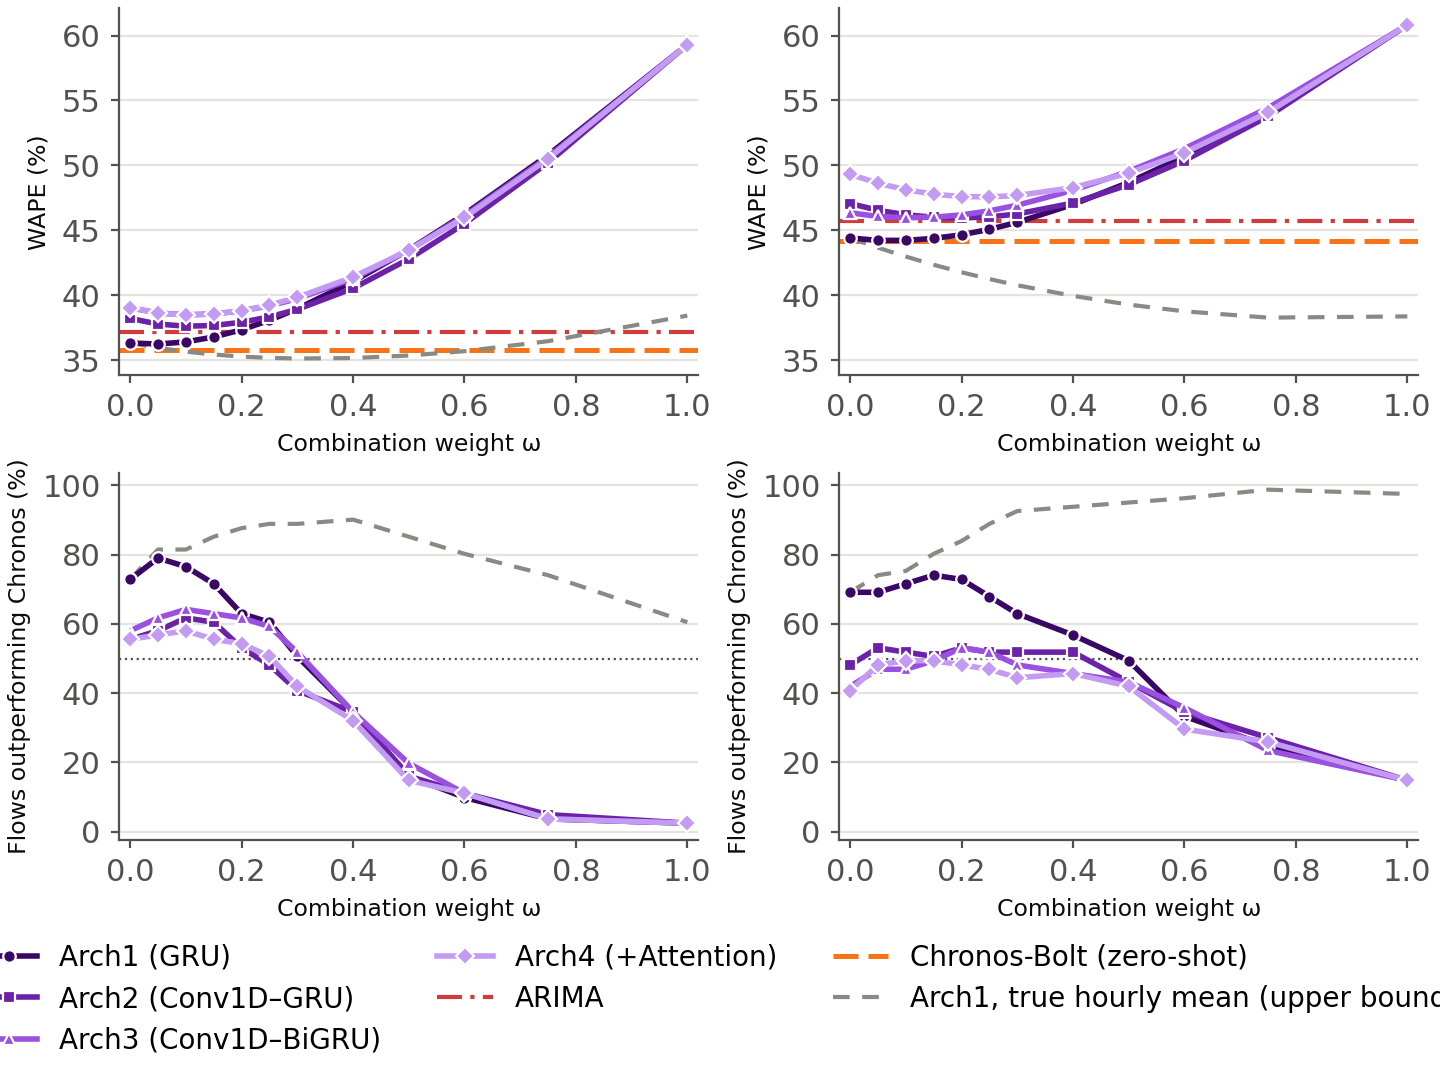

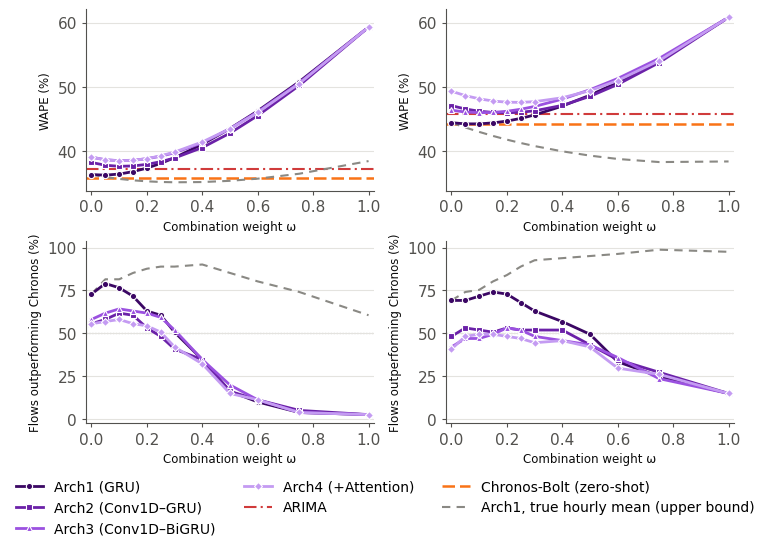

In [1]:
# ============================================================
# Figura_combinacion_omega.py — v2.11
# Figura 2×2, modo A:
#   (a)/(c) WAPE (%) en función de ω, T+5 y T+15
#   (b)/(d) % de enlaces que ganan a ARIMA en función de ω, T+5 y T+15
#   ŷ = (1 − ω)·Prediccion + ω·Hora_<FUENTE>          (movil60 = sin fuga)
#   Línea gris discontinua: Arq1 con Hora_<FUENTE_COTA> (real = con fuga, cota superior)
# Datos: Results_min_Base/.../test_..._w00_H*_<enlace>.csv (TestArq_min_mezcla v1.1),
#        columnas Realidad, Prediccion, Hora_movil60, Hora_real, ...
# Mismos instantes para todos (inner join con ARIMA), Realidad > TRIGGER.
#   WAPE      → Σ|error| / Σ real, sumando todos los enlaces
#   % gana    → enlaces en los que el modelo tiene menor CRITERIO (MAE o MAPE) que ARIMA
# Salida: Figura_combinacion_omega.pdf/.png y Figura_combinacion_omega_datos.csv
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

ROOT_RESULTS = "Results_min_Base"
DIR_BASE     = "Results_min_Base/results_baselines_1min"
CARPETA      = "results_Arq{ID}_{H}m_{MODO}_W60_w00_H{H}"
IDS          = [1, 2, 3, 4]
HORIZONTES   = [5, 15]
MODO         = "A"
TRIGGER      = 1000
OMEGAS       = [0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30,0.4, 0.50, 0.6, 0.75, 1.0]
FUENTE       = "pred"     # pred | movil60 | hora_ant   (sin fuga)
FUENTE_COTA  = "real"        # línea gris (Arq1). None para no dibujarla
CRITERIO     = "WAPE"        # WAPE / MAE (mismo resultado por enlace) o MAPE para decidir si gana a ARIMA
SALIDA       = "Figura_combinacion_omega"
DIR_PLOTS    = "plots"       # aquí se guarda cada gráfica en un PDF
TAM_EJES     = 11            # tamaño de los números de los ejes
TAM_LEYENDA  = 10            # tamaño de la leyenda
CHRONOS      = "Results_min_Base/results_chronos-bolt-small_C60_{H}m"   # None para no dibujarla
# Predicción horaria para FUENTE = "pred" (None = la guardada en el test):
DIR_HORARIO  = "Results_horas/results_Arq1_1h_A_W24"
REFERENCIA   = "Chronos"     # Chronos | ARIMA : contra quién se cuentan las victorias en (b)/(d)
#   otros: "Results_horas/results_Arq3_1h_B_W24", "Results_horas/results_chronos-bolt-small_C168_1h", …


def curvas(ID, H, fuente):
    """WAPE y % de enlaces que ganan a ARIMA para cada ω, y WAPE de ARIMA."""
    d = os.path.join(ROOT_RESULTS, CARPETA.format(ID=ID, H=H, MODO=MODO))
    if not os.path.isdir(d):
        print(f"⚠️ falta {d}")
        return None
    pref = "test_" + os.path.basename(d).removeprefix("results_") + "_"
    col_h = f"Hora_{fuente}"
    al_vuelo = fuente == "pred" and DIR_HORARIO is not None
    ph = "test_" + os.path.basename(DIR_HORARIO.rstrip("/")).removeprefix("results_") + "_" if al_vuelo else None
    se, sy, se_a, se_c = np.zeros(len(OMEGAS)), 0.0, 0.0, 0.0
    gana, n, gana_c = np.zeros(len(OMEGAS)), 0, 0
    dc = CHRONOS.format(H=H) if CHRONOS else None
    pc = "test_" + os.path.basename(dc).removeprefix("results_") + "_" if dc else None
    for f in sorted(os.listdir(d)):
        if not (f.startswith(pref) and f.endswith(".csv")):
            continue
        e = f[len(pref):-4]
        fb = os.path.join(DIR_BASE, f"test_results_{e}_baselines.csv")
        if not os.path.exists(fb):
            continue
        j = pd.read_csv(os.path.join(d, f), parse_dates=["timestamp"]).set_index("timestamp")
        if al_vuelo:
            fh = os.path.join(DIR_HORARIO, f"{ph}{e}.csv")
            if not os.path.exists(fh):
                print(f"⚠️ falta horario {fh}: enlace fuera"); continue
            m = pd.read_csv(fh, parse_dates=["timestamp"]).set_index("timestamp")["Prediccion"]
            t_obs = j.index - pd.Timedelta(minutes=H)                     # último minuto observado
            j[col_h] = m.reindex(t_obs.ceil("h")).ffill().bfill().values
        elif col_h not in j.columns:
            print(f"❌ {f} no tiene la columna {col_h}"); return None
        b = pd.read_csv(fb, parse_dates=["timestamp"]).set_index("timestamp")
        j = j[["Realidad", "Prediccion", col_h]].join(
            b[[f"ARIMA_t+{H}"]].rename(columns={f"ARIMA_t+{H}": "ARIMA"}), how="inner")
        if dc:
            fc = os.path.join(dc, f"{pc}{e}.csv")
            if not os.path.exists(fc):
                print(f"⚠️ falta Chronos {fc}: enlace fuera"); continue
            c = pd.read_csv(fc, parse_dates=["timestamp"]).set_index("timestamp")[["Prediccion"]]
            j = j.join(c.rename(columns={"Prediccion": "Chronos"}), how="inner")
        j = j.dropna()
        j = j[j["Realidad"] > TRIGGER]
        if j.empty:
            continue
        y, p, h, a = (j[c].values for c in ["Realidad", "Prediccion", col_h, "ARIMA"])
        medida = (lambda e: np.mean(e / y)) if CRITERIO == "MAPE" else (lambda e: e.mean())
        ea = np.abs(y - a)
        err_a = medida(ea)
        sy += y.sum(); se_a += ea.sum(); n += 1
        err_ref = err_a
        if dc:
            ec = np.abs(y - j["Chronos"].values)
            se_c += ec.sum(); gana_c += medida(ec) < err_a
            if REFERENCIA == "Chronos":
                err_ref = medida(ec)
        for k, w in enumerate(OMEGAS):
            err = np.abs(y - ((1 - w) * p + w * h))
            se[k] += err.sum()
            gana[k] += medida(err) < err_ref
    if n == 0:
        return None
    return (100 * se / sy, 100 * gana / n, n, 100 * se_a / sy,
            100 * se_c / sy if dc else None, 100 * gana_c / n if dc else None)


# ---------------- cálculo ----------------
if REFERENCIA == "Chronos" and not CHRONOS:
    raise SystemExit("❌ REFERENCIA = 'Chronos' necesita CHRONOS")
datos, filas = {}, []
for H in HORIZONTES:
    for ID in IDS:
        r = curvas(ID, H, FUENTE)
        if r is not None:
            datos[(H, ID)] = r
            filas += [{"H": H, "Arq": ID, "fuente": FUENTE, "ω": w, "WAPE": r[0][k],
                       "% gana ARIMA": r[1][k], "enlaces": r[2]} for k, w in enumerate(OMEGAS)]
    if FUENTE_COTA:
        r = curvas(1, H, FUENTE_COTA)
        if r is not None:
            datos[(H, "cota")] = r
            filas += [{"H": H, "Arq": 1, "fuente": FUENTE_COTA, "ω": w, "WAPE": r[0][k],
                       "% gana ARIMA": r[1][k], "enlaces": r[2]} for k, w in enumerate(OMEGAS)]
tabla = pd.DataFrame(filas)
tabla[["WAPE", "% gana ARIMA"]] = tabla[["WAPE", "% gana ARIMA"]].round(1)
tabla.to_csv(f"{SALIDA}_datos.csv", index=False)
print(f"💾 {SALIDA}_datos.csv")

# ---------------- por pantalla ----------------
pd.set_option("display.width", 250)
for H in HORIZONTES:
    t = tabla[tabla["H"] == H]
    idx = t["fuente"].map(lambda f: "cota" if f == FUENTE_COTA and FUENTE_COTA != FUENTE else "") + \
          t["Arq"].map(lambda a: f"Arch{a}")
    t = t.assign(Modelo=idx.str.replace("cotaArch1", f"Arch1 ({FUENTE_COTA}, cota)"))
    print(f"\n========== T+{H} min · modo {MODO} · ω con '{FUENTE}'"
          + (f" ({DIR_HORARIO})" if FUENTE == "pred" and DIR_HORARIO else "")
          + f" · {t['enlaces'].iloc[0]} enlaces ==========")
    if (H, 1) in datos:
        print(f"WAPE ARIMA: {datos[(H, 1)][3]:.1f} %")
        if datos[(H, 1)][4] is not None:
            print(f"Chronos: WAPE {datos[(H, 1)][4]:.1f} % · gana a ARIMA en {datos[(H, 1)][5]:.1f} % de los enlaces")
    print("WAPE (%)")
    print(t.pivot_table(index="Modelo", columns="ω", values="WAPE", sort=False).to_string())
    print(f"% de enlaces que ganan a {REFERENCIA} (criterio {CRITERIO})")
    print(t.pivot_table(index="Modelo", columns="ω", values="% gana ARIMA", sort=False).to_string())

# ---------------- figura ----------------
NOMBRES = {1: "Arch1 (GRU)", 2: "Arch2 (Conv1D–GRU)", 3: "Arch3 (Conv1D–BiGRU)", 4: "Arch4 (+Attention)"}
COLOR   = {1: "#3b0764", 2: "#6b21a8", 3: "#9b51e0", 4: "#c49bf2"}   # morado, de oscuro a claro
MARCA   = {1: "o", 2: "s", 3: "^", 4: "D"}
TINTA, TINTA2, REJILLA, GRIS, ROJO = "#0b0b0b", "#52514e", "#e4e3df", "#8a8984", "#d03b3b"
NARANJA = "#f97316"
COTA_TXT = {"real": "Arch1, true hourly mean (upper bound)", "pred": "Arch1, hourly forecast",
            "movil60": "Arch1, last-60-min mean", "hora_ant": "Arch1, last complete hour"}

# mismos límites Y en las dos gráficas de cada columna (mín y máx de las dos)
LIM = []
for col in (0, 1):
    v = [x for k, r in datos.items() for x in r[col]]
    if col == 0:
        v += [datos[(H, 1)][3] for H in HORIZONTES if (H, 1) in datos]
    v += [datos[(H, 1)][4 + col] for H in HORIZONTES
          if (H, 1) in datos and datos[(H, 1)][4 + col] is not None and (col == 0 or REFERENCIA == "ARIMA")]
    lo, hi = min(v), max(v)
    m = 0.05 * (hi - lo)
    LIM.append((lo - m, hi + m))

def panel(ax, H, col):
    ylab = ["WAPE (%)", f"Flows outperforming {REFERENCIA} (%)"][col]
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(TINTA2); ax.spines[s].set_linewidth(0.8)
    ax.tick_params(colors=TINTA2, labelsize=TAM_EJES, length=3)
    ax.yaxis.grid(True, color=REJILLA, linewidth=0.8); ax.set_axisbelow(True)

    if col == 0 and (H, 1) in datos:
        ax.axhline(datos[(H, 1)][3], color=ROJO, linewidth=1.5, linestyle=(0, (6, 2, 1, 2)),
                   label="ARIMA", zorder=1)
    if (H, 1) in datos and datos[(H, 1)][4 + col] is not None and (col == 0 or REFERENCIA == "ARIMA"):
        ax.axhline(datos[(H, 1)][4 + col], color=NARANJA, linewidth=1.8, linestyle=(0, (5, 2)),
                   label="Chronos-Bolt (zero-shot)", zorder=1)
    if (H, "cota") in datos:
        ax.plot(OMEGAS, datos[(H, "cota")][col], color=GRIS, linewidth=1.5, linestyle=(0, (4, 3)),
                label=COTA_TXT[FUENTE_COTA], zorder=1)
    for ID in IDS:
        if (H, ID) in datos:
            ax.plot(OMEGAS, datos[(H, ID)][col], color=COLOR[ID], marker=MARCA[ID], markersize=4.5,
                    linewidth=2, label=NOMBRES[ID], zorder=2,
                    markeredgecolor="white", markeredgewidth=0.8)
    if col == 1:
        ax.axhline(50, color=TINTA2, linewidth=0.8, linestyle=":", zorder=0)
    ax.set_ylim(*LIM[col])
    ax.set_xlim(-0.02, 1.02)
    ax.set_xlabel("Combination weight ω", fontsize=8.5, color=TINTA)
    ax.set_ylabel(ylab, fontsize=8.5, color=TINTA)


def leyenda_ordenada(h, l):
    orden = [i for i, t in enumerate(l) if t in NOMBRES.values()] + \
            [i for i, t in enumerate(l) if t not in NOMBRES.values()]
    return [h[i] for i in orden], [l[i] for i in orden]


# ---- cada gráfica en su propio PDF (DIR_PLOTS) ----
# letras: (a) WAPE T+5, (b) WAPE T+15, (c) gana T+5, (d) gana T+15
os.makedirs(DIR_PLOTS, exist_ok=True)
for col, nom in enumerate(["WAPE", f"gana_{REFERENCIA}"]):
    for k, H in enumerate(HORIZONTES):
        letra = chr(97 + len(HORIZONTES) * col + k)
        f1, ax = plt.subplots(figsize=(4.4, 3.6), constrained_layout=True)
        panel(ax, H, col)
        hh, ll = leyenda_ordenada(*ax.get_legend_handles_labels())
        ll = [t.replace(" (upper bound)", "\n(upper bound)") for t in ll]   # que quepa en 2 columnas
        f1.legend(hh, ll, loc="outside lower center", ncol=2, frameon=False, fontsize=TAM_LEYENDA,
                  handlelength=1.6, columnspacing=1.0, handletextpad=0.5)
        ruta = os.path.join(DIR_PLOTS, f"{SALIDA}_{letra}_T{H}_{nom}.pdf")
        f1.savefig(ruta)
        plt.close(f1)
        print(f"💾 {ruta}")

# ---- figura completa 2×2: fila 1 = WAPE (a, b), fila 2 = % que ganan (c, d) ----
fig, axes = plt.subplots(2, len(HORIZONTES), figsize=(7.2, 5.4),
                         constrained_layout=True, squeeze=False)
for col in (0, 1):
    for k, H in enumerate(HORIZONTES):
        panel(axes[col, k], H, col)

h, l = axes[0, 0].get_legend_handles_labels()
h2, l2 = axes[1, 0].get_legend_handles_labels()
h += [x for x, t in zip(h2, l2) if t not in l]; l += [t for t in l2 if t not in l]
fig.legend(*leyenda_ordenada(h, l), loc="outside lower center",
           ncol=3, frameon=False, fontsize=TAM_LEYENDA)
fig.savefig(f"{SALIDA}.pdf")
fig.savefig(f"{SALIDA}.png", dpi=200)
print(f"💾 {SALIDA}.pdf / .png")
try:                                    # en Jupyter se muestra siempre, aunque el backend sea Agg
    from IPython.display import display, Image
    get_ipython()
    display(Image(filename=f"{SALIDA}.png"))
except NameError:
    plt.show()

In [1]:
# ============================================================
# Tests_estadisticos.py — v1.0
# Tests estadísticos para R4.8 / R5.7 / R1.5 (no usa GPU, solo lee los CSV de test guardados).
#
# Qué hace, para cada comparación "modelo frente a referencia" sobre los flujos:
#   1. WAPE de cada flujo para los dos modelos, en los mismos instantes que las tablas y figuras.
#   2. Test de Wilcoxon de rangos con signo, pareado por flujo (bilateral): ¿las diferencias de
#      WAPE por flujo están sistemáticamente a un lado? No supone normalidad.
#   3. Tamaño del efecto:
#        - mediana de la diferencia de WAPE por flujo (referencia − modelo, en puntos; > 0 = el
#          modelo es mejor) con IC del 95 % por bootstrap sobre los flujos;
#        - correlación biserial de rangos r (de −1 a 1; > 0 = el modelo es mejor).
#   4. Diferencia del WAPE GLOBAL (Σ|e|/Σy, el de las tablas) con IC del 95 % por bootstrap sobre
#      los flujos: dice si una diferencia como la de Chronos frente a Arch1_A (0.5 puntos) es real.
#   5. Corrección de Holm por comparaciones múltiples, dentro de cada familia (las comparaciones
#      de una misma arquitectura en esa parte) y, como referencia, sobre toda la parte.
#
# Partes (cada una se salta si no está su carpeta; BRAIN y Abilene van en carpetas distintas):
#   "min"     BRAIN, minutos, ω = 0: Arch1–4 (A) frente a ARIMA y Chronos, T+5 y T+15.
#             Instantes comunes de las 8 arquitecturas + ARIMA + Chronos (= Tablas 4–6 y apéndice).
#   "omega"   BRAIN, combinación jerárquica de Arch1_A con la hora de Arch1_A W24 (= Figs. 2 y 3):
#             cada ω de OMEGAS frente a ω = 0 y frente a Chronos, T+5 y T+15.
#   "hora"    BRAIN, nivel horario, W = 24: las 8 configuraciones frente a ARIMA y Chronos (= Tablas 2 y 3).
#   "abilene" Abilene, ω = 0: Arch1–4 (A) frente a ARIMA y Chronos, T+5 y T+15 (= Fig. 4 con ω = 0).
#
# Ejecutar desde la carpeta de los resultados (la de BRAIN o la de Abilene):
#     python Tests_estadisticos.py
# Salida: tablas por pantalla y Tests_estadisticos.csv
# ============================================================
import os
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon, rankdata

PARTES  = ["min", "omega", "hora", "abilene"]
B_BOOT  = 5000          # remuestras bootstrap
SEMILLA = 0
SALIDA  = "Tests_estadisticos.csv"
IDS     = [1, 2, 3, 4]

MIN = dict(ROOT="Results_min_Base", BASE="Results_min_Base/results_baselines_1min",
           CARPETA="results_Arq{ID}_{H}m_{M}_W60_w00_H{H}", CHRONOS="results_chronos-bolt-small_C60_{H}m",
           ARIMA="ARIMA_t+{H}", TRIGGER=1000, HORIZONTES=[5, 15], MASCARA=["A", "B"])
OMEGA = dict(DIR_HORARIO="Results_horas/results_Arq1_1h_A_W24", OMEGAS=[0.05, 0.10, 0.15, 0.20])
HORA = dict(ROOT="Results_horas", BASE="Results_horas/results_baselines_1h",
            CARPETA="results_Arq{ID}_1h_{M}_W{W}", CHRONOS="results_chronos-bolt-small_C{W}_1h",
            ARIMA="ARIMA_t+1", TRIGGER=1000, W=24, MASCARA=["A", "B"])
ABILENE = dict(ROOT="Results_min_Abilene", BASE="Results_min_Abilene/results_baselines_5min",
               CARPETA="results_Arq{ID}_{H}m_A_W60_w00_H{H}", CHRONOS="results_chronos-bolt-small_C12_{H}m",
               ARIMA="ARIMA_t+{P}", TRIGGER=0.001, HORIZONTES=[5, 15])      # P = H/5 pasos de 5 min

rng = np.random.default_rng(SEMILLA)


# ---------------- utilidades ----------------
def es_flujo(e):
    p = e.split("_")
    return len(p) == 2 and all(len(x) >= 2 for x in p)


def flujos_chronos(root, carpeta):
    d = os.path.join(root, carpeta)
    pref = "test_" + os.path.basename(d).removeprefix("results_") + "_"
    return {f[len(pref):-4]: os.path.join(d, f) for f in sorted(os.listdir(d))
            if f.startswith(pref) and f.endswith(".csv") and es_flujo(f[len(pref):-4])}


def ruta_test(root, carpeta, e):
    return os.path.join(root, carpeta, f"test_{carpeta.removeprefix('results_')}_{e}.csv")


def leer(f, col, nombre):
    return pd.read_csv(f, parse_dates=["timestamp"]).set_index("timestamp")[[col]].rename(columns={col: nombre})


def holm(p):
    p = np.asarray(p, float)
    out = np.full(len(p), np.nan)
    ok = ~np.isnan(p)
    q, m = p[ok], ok.sum()
    orden = np.argsort(q)
    adj, run = np.empty(m), 0.0
    for k, j in enumerate(orden):
        run = max(run, min(1.0, (m - k) * q[j]))
        adj[j] = run
    out[ok] = adj
    return out


def comparar(se_m, se_r, sy):
    """se_m, se_r: Σ|e| por flujo del modelo y de la referencia; sy: Σy por flujo (mismos instantes)."""
    se_m, se_r, sy = map(np.asarray, (se_m, se_r, sy))
    d = 100 * (se_r - se_m) / sy                     # > 0: el modelo tiene menor WAPE en ese flujo
    n = len(d)
    nz = d[d != 0]
    if len(nz) == 0:
        p, r = np.nan, 0.0
    else:
        p = wilcoxon(nz).pvalue
        rk = rankdata(np.abs(nz))
        r = (rk[nz > 0].sum() - rk[nz < 0].sum()) / rk.sum()
    idx = rng.integers(0, n, size=(B_BOOT, n))
    med_b = np.median(d[idx], axis=1)
    glob = 100 * (se_r.sum() - se_m.sum()) / sy.sum()
    glob_b = 100 * (se_r[idx].sum(1) - se_m[idx].sum(1)) / sy[idx].sum(1)
    return {"N": n, "Gana": int((d > 0).sum()), "Pierde": int((d < 0).sum()),
            "Pct_gana": round(100 * (d > 0).mean(), 1),
            "dWAPE_flujo_med": np.median(d), "IC_lo": np.percentile(med_b, 2.5), "IC_hi": np.percentile(med_b, 97.5),
            "r_rb": r, "p": p,
            "dWAPE_global": glob, "IC_glob_lo": np.percentile(glob_b, 2.5), "IC_glob_hi": np.percentile(glob_b, 97.5)}


def acumular(j, cols):
    y = j["Realidad"].values
    return {c: np.abs(y - j[c].values).sum() for c in cols}, y.sum()


# ---------------- partes ----------------
def parte_min():
    C, filas = MIN, []
    for H in C["HORIZONTES"]:
        se, sy = {}, []
        for e, fc in flujos_chronos(C["ROOT"], C["CHRONOS"].format(H=H)).items():
            j = None
            for ID in IDS:
                for M in C["MASCARA"]:
                    f = ruta_test(C["ROOT"], C["CARPETA"].format(ID=ID, H=H, M=M), e)
                    if os.path.exists(f):
                        t = pd.read_csv(f, parse_dates=["timestamp"]).set_index("timestamp")[["Realidad", "Prediccion"]]
                        t = t.rename(columns={"Prediccion": f"Arch{ID}_{M}"})
                        j = t if j is None else j.join(t.drop(columns="Realidad"), how="inner")
            fb = os.path.join(C["BASE"], f"test_results_{e}_baselines.csv")
            if j is None or not os.path.exists(fb):
                continue
            j = j.join(leer(fb, C["ARIMA"].format(H=H), "ARIMA"), how="inner").join(
                leer(fc, "Prediccion", "Chronos"), how="inner").dropna()
            j = j[j["Realidad"] > C["TRIGGER"]]
            if j.empty:
                continue
            s, y = acumular(j, [c for c in j.columns if c != "Realidad"])
            for k, v in s.items():
                se.setdefault(k, []).append(v)
            sy.append(y)
        print(f"   min T+{H}: {len(sy)} flujos | WAPE global: " +
              " | ".join(f"{k} {100 * sum(v) / sum(sy):.1f}" for k, v in sorted(se.items()) if k.endswith("_A") or k in ("ARIMA", "Chronos")))
        for ID in IDS:
            m = f"Arch{ID}_A"
            if m not in se:
                continue
            for ref in ("ARIMA", "Chronos"):
                filas.append({"Parte": "min", "Horizonte": f"T+{H}", "Modelo": m, "Referencia": ref,
                              "Familia": f"min_{m}", **comparar(se[m], se[ref], sy)})
    return filas


def parte_omega():
    C, filas = MIN, []
    dh = OMEGA["DIR_HORARIO"]
    ph = "test_" + os.path.basename(dh.rstrip("/")).removeprefix("results_") + "_"
    for H in C["HORIZONTES"]:
        cols = ["w0"] + [f"w{w:.2f}" for w in OMEGA["OMEGAS"]]
        se, sy = {}, []
        for e, fc in flujos_chronos(C["ROOT"], C["CHRONOS"].format(H=H)).items():
            f = ruta_test(C["ROOT"], C["CARPETA"].format(ID=1, H=H, M="A"), e)
            fb = os.path.join(C["BASE"], f"test_results_{e}_baselines.csv")
            fh = os.path.join(dh, f"{ph}{e}.csv")
            if not (os.path.exists(f) and os.path.exists(fb) and os.path.exists(fh)):
                continue
            j = pd.read_csv(f, parse_dates=["timestamp"]).set_index("timestamp")[["Realidad", "Prediccion"]]
            m = pd.read_csv(fh, parse_dates=["timestamp"]).set_index("timestamp")["Prediccion"]
            t_obs = j.index - pd.Timedelta(minutes=H)                  # como Figura_combinacion_omega
            j["Hora"] = m.reindex(t_obs.ceil("h")).ffill().bfill().values
            j = j.join(leer(fb, C["ARIMA"].format(H=H), "ARIMA"), how="inner").join(
                leer(fc, "Prediccion", "Chronos"), how="inner").dropna()
            j = j[j["Realidad"] > C["TRIGGER"]]
            if j.empty:
                continue
            j["w0"] = j["Prediccion"]
            for w in OMEGA["OMEGAS"]:
                j[f"w{w:.2f}"] = (1 - w) * j["Prediccion"] + w * j["Hora"]
            s, y = acumular(j, cols + ["Chronos"])
            for k, v in s.items():
                se.setdefault(k, []).append(v)
            sy.append(y)
        if not sy:
            continue
        print(f"   omega T+{H}: {len(sy)} flujos | WAPE global Arch1_A: " +
              " | ".join(f"{k} {100 * sum(se[k]) / sum(sy):.1f}" for k in cols) +
              f" | Chronos {100 * sum(se['Chronos']) / sum(sy):.1f}")
        for w in OMEGA["OMEGAS"]:
            k = f"w{w:.2f}"
            filas.append({"Parte": "omega", "Horizonte": f"T+{H}", "Modelo": f"Arch1_A ω={w:.2f}",
                          "Referencia": "Arch1_A ω=0", "Familia": f"omega_T{H}_vs_w0", **comparar(se[k], se["w0"], sy)})
            filas.append({"Parte": "omega", "Horizonte": f"T+{H}", "Modelo": f"Arch1_A ω={w:.2f}",
                          "Referencia": "Chronos", "Familia": f"omega_T{H}_vs_Chronos", **comparar(se[k], se["Chronos"], sy)})
    return filas


def parte_hora():
    C, W, filas = HORA, HORA["W"], []
    se, sy = {}, []
    for e, fc in flujos_chronos(C["ROOT"], C["CHRONOS"].format(W=W)).items():
        j = None
        for ID in IDS:
            for M in C["MASCARA"]:
                f = ruta_test(C["ROOT"], C["CARPETA"].format(ID=ID, M=M, W=W), e)
                if os.path.exists(f):
                    t = pd.read_csv(f, parse_dates=["timestamp"]).set_index("timestamp")[["Realidad", "Prediccion"]]
                    t = t.rename(columns={"Prediccion": f"Arch{ID}_{M}"})
                    j = t if j is None else j.join(t.drop(columns="Realidad"), how="inner")
        fb = os.path.join(C["BASE"], f"test_results_{e}_baselines.csv")
        if j is None or not os.path.exists(fb):
            continue
        j = j.join(leer(fb, C["ARIMA"], "ARIMA"), how="inner").join(leer(fc, "Prediccion", "Chronos"), how="inner").dropna()
        j = j[j["Realidad"] > C["TRIGGER"]]
        if j.empty:
            continue
        s, y = acumular(j, [c for c in j.columns if c != "Realidad"])
        for k, v in s.items():
            se.setdefault(k, []).append(v)
        sy.append(y)
    print(f"   hora W={W}: {len(sy)} flujos | WAPE global: " +
          " | ".join(f"{k} {100 * sum(v) / sum(sy):.1f}" for k, v in sorted(se.items())))
    for ID in IDS:
        for M in C["MASCARA"]:
            m = f"Arch{ID}_{M}"
            if m not in se:
                continue
            for ref in ("ARIMA", "Chronos"):
                filas.append({"Parte": "hora", "Horizonte": "T+1 h", "Modelo": m, "Referencia": ref,
                              "Familia": f"hora_{m}", **comparar(se[m], se[ref], sy)})
    return filas


def parte_abilene():
    C, filas = ABILENE, []
    for H in C["HORIZONTES"]:
        for ID in IDS:
            se, sy = {}, []
            for e, fc in flujos_chronos(C["ROOT"], C["CHRONOS"].format(H=H)).items():
                f = ruta_test(C["ROOT"], C["CARPETA"].format(ID=ID, H=H), e)
                fb = os.path.join(C["BASE"], f"test_results_{e}_baselines.csv")
                if not (os.path.exists(f) and os.path.exists(fb)):
                    continue
                j = pd.read_csv(f, parse_dates=["timestamp"]).set_index("timestamp")[["Realidad", "Prediccion"]]
                j = j.rename(columns={"Prediccion": "Modelo"}).join(leer(fb, C["ARIMA"].format(P=H // 5), "ARIMA"), how="inner").join(
                    leer(fc, "Prediccion", "Chronos"), how="inner").dropna()
                j = j[j["Realidad"] > C["TRIGGER"]]
                if j.empty:
                    continue
                s, y = acumular(j, ["Modelo", "ARIMA", "Chronos"])
                for k, v in s.items():
                    se.setdefault(k, []).append(v)
                sy.append(y)
            if not sy:
                continue
            print(f"   abilene T+{H} Arch{ID}_A: {len(sy)} flujos | WAPE global: Arch{ID}_A "
                  f"{100 * sum(se['Modelo']) / sum(sy):.1f} | ARIMA {100 * sum(se['ARIMA']) / sum(sy):.1f} | "
                  f"Chronos {100 * sum(se['Chronos']) / sum(sy):.1f}")
            for ref in ("ARIMA", "Chronos"):
                filas.append({"Parte": "abilene", "Horizonte": f"T+{H}", "Modelo": f"Arch{ID}_A", "Referencia": ref,
                              "Familia": f"abilene_Arch{ID}_A", **comparar(se["Modelo"], se[ref], sy)})
    return filas


# ---------------- ejecución ----------------
CARPETAS = {"min": MIN["ROOT"], "omega": OMEGA["DIR_HORARIO"], "hora": HORA["ROOT"], "abilene": ABILENE["ROOT"]}
FUNCIONES = {"min": parte_min, "omega": parte_omega, "hora": parte_hora, "abilene": parte_abilene}
filas = []
print("Instantes y WAPE global de control (deben coincidir con las tablas y figuras del paper):")
for parte in PARTES:
    if not os.path.isdir(CARPETAS[parte]) or (parte == "omega" and not os.path.isdir(MIN["ROOT"])):
        print(f"   ⏩ {parte}: no está {CARPETAS[parte]}, se salta")
        continue
    filas += FUNCIONES[parte]()

if not filas:
    raise SystemExit("❌ No se ha encontrado ninguna carpeta de resultados")
df = pd.DataFrame(filas)
df["p_Holm"] = np.nan
for fam, g in df.groupby("Familia"):
    df.loc[g.index, "p_Holm"] = holm(g["p"].values)
df["p_Holm_parte"] = np.nan
for parte, g in df.groupby("Parte"):
    df.loc[g.index, "p_Holm_parte"] = holm(g["p"].values)
df.to_csv(SALIDA, index=False)

pd.set_option("display.width", 250)
for parte, g in df.groupby("Parte", sort=False):
    print(f"\n{'=' * 118}\n  {parte.upper()}  (dWAPE = referencia − modelo, en puntos; > 0 = el modelo es mejor)\n{'=' * 118}")
    print(f"{'Horiz.':>7} {'Modelo':>18} {'vs':>12} {'N':>4} {'%gana':>6} "
          f"{'dWAPE flujo (mediana) [IC95]':>30} {'r':>6} {'p':>9} {'p_Holm':>9} {'p_Holm_parte':>12} "
          f"{'dWAPE global [IC95]':>24}")
    for _, x in g.iterrows():
        print(f"{x['Horizonte']:>7} {x['Modelo']:>18} {x['Referencia']:>12} {x['N']:>4} {x['Pct_gana']:>6.1f} "
              f"{x['dWAPE_flujo_med']:>+9.2f} [{x['IC_lo']:+.2f}, {x['IC_hi']:+.2f}]{'':>3} "
              f"{x['r_rb']:>+6.2f} {x['p']:>9.2g} {x['p_Holm']:>9.2g} {x['p_Holm_parte']:>12.2g} "
              f"{x['dWAPE_global']:>+8.2f} [{x['IC_glob_lo']:+.2f}, {x['IC_glob_hi']:+.2f}]")
print(f"\n💾 {SALIDA}")

Instantes y WAPE global de control (deben coincidir con las tablas y figuras del paper):
   min T+5: 81 flujos | WAPE global: ARIMA 37.1 | Arch1_A 36.3 | Arch2_A 38.2 | Arch3_A 39.0 | Arch4_A 39.0 | Chronos 35.8
   min T+15: 81 flujos | WAPE global: ARIMA 45.7 | Arch1_A 44.4 | Arch2_A 47.1 | Arch3_A 46.3 | Arch4_A 49.3 | Chronos 44.2
   omega T+5: 81 flujos | WAPE global Arch1_A: w0 36.3 | w0.05 36.2 | w0.10 36.4 | w0.15 36.8 | w0.20 37.3 | Chronos 35.8
   omega T+15: 81 flujos | WAPE global Arch1_A: w0 44.4 | w0.05 44.2 | w0.10 44.2 | w0.15 44.4 | w0.20 44.7 | Chronos 44.2
   hora W=24: 81 flujos | WAPE global: ARIMA 46.8 | Arch1_A 43.1 | Arch1_B 42.4 | Arch2_A 42.4 | Arch2_B 42.7 | Arch3_A 41.3 | Arch3_B 42.0 | Arch4_A 40.9 | Arch4_B 43.3 | Chronos 41.8
   ⏩ abilene: no está Results_min_Abilene, se salta

  MIN  (dWAPE = referencia − modelo, en puntos; > 0 = el modelo es mejor)
 Horiz.             Modelo           vs    N  %gana   dWAPE flujo (mediana) [IC95]      r         p    p_Ho

A) FIGURA REAL FRENTE A PREDICHO: (a) hora, t+1 h, 7 días | (b) minuto, T+5, 4 h
   Flujos de volumen alto (media > percentil 75) en los que Arch1 gana a ARIMA y a Chronos en los dos niveles: 4 de 21
   (h_ = WAPE horario, m_ = WAPE de minuto; ventaja = mejor referencia − Arch1, en puntos)
          media_Mbps  h_Arch1_A  h_ARIMA  h_Chronos  m_Arch1_A  m_ARIMA  m_Chronos  ventaja_h  ventaja_m
flujo                                                                                                   
HTW_HTW          2.3       36.0     46.4       42.2       47.1     50.5       48.3        6.2        1.1
SPK_WIAS         4.5       49.3     65.6       57.5       45.9     48.0       46.3        8.2        0.4
SPK_ZIB          2.3       40.8     46.3       43.0       50.1     53.9       50.9        2.2        0.8
SPK_HTW          0.9       51.8     62.6       52.5       51.8     61.6       53.8        0.7        2.0

   Flujo: HTW_HTW
   (a) 2013-02-26 13:00:00 → 2013-03-05 12:00:00 | WAPE vent

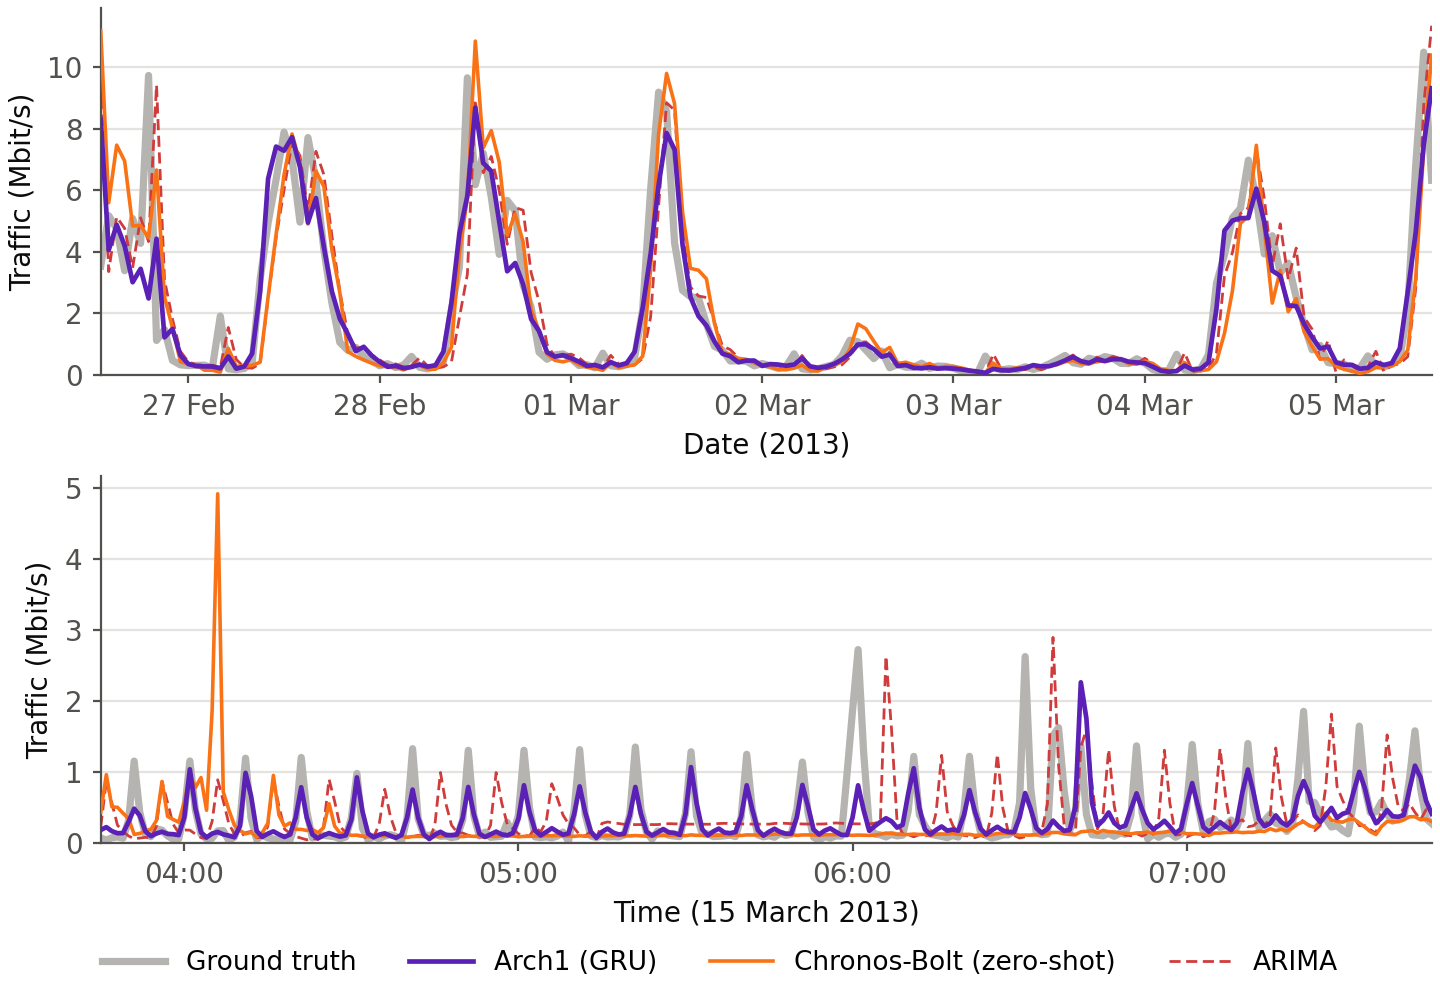

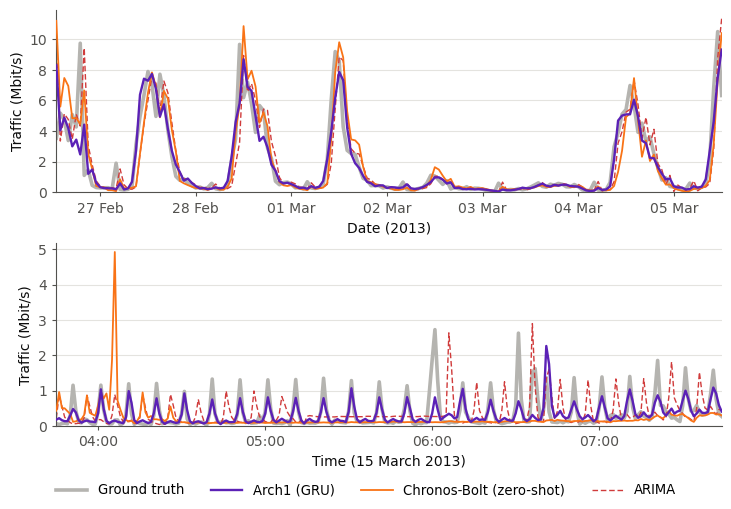

In [3]:
# ============================================================
# Figura_real_pred_Spearman.py — v1.4  (BRAIN; no usa GPU)
# v1.4: INICIO_H e INICIO_MIN para fijar a mano el inicio de cada ventana (None = la automática).
# v1.3: elección FAVORABLE a Arch1, pero real:
#       - Flujo: entre los de volumen alto (cuartil superior), los que Arch1 gana a ARIMA y a Chronos
#         en los DOS niveles (horario y minuto), ordenados por la suma de las ventajas relativas.
#         Se imprimen los 10 primeros por si prefieres otro (FLUJO = "...").
#       - Ventanas: la semana (panel a) y las 4 h (panel b) en las que Arch1 tiene más ventaja en WAPE
#         sobre la mejor de las dos referencias.
# v1.2: la figura pasa a enseñar los DOS NIVELES del marco con el MISMO flujo:
#       (a) nivel horario: una semana del test, t+1 h, Arch1_A (W = 24, el nivel horario del marco),
#           ARIMA y Chronos (C = 24). Se ve el ciclo diario y cómo lo siguen los modelos.
#       (b) nivel de minuto: VENTANA_HORAS (4 h) en T+H_MIN (5 min), Arch1_A (ω = 0), ARIMA y Chronos.
#       - FLUJO = None → entre los flujos de más volumen (cuartil superior), el de ciclo diario más
#         marcado (autocorrelación horaria a 24 h). Se imprime la lista de candidatos con su
#         autocorrelación y el WAPE de cada modelo en los dos niveles, por si quieres otro.
#       - HACER_SPEARMAN = False: los números de Spearman ya están; True para repetirlos.
# v1.1: flujos de más volumen, ventana de tráfico típico, líneas más legibles, LOG_Y.
# v1.0: primera versión.
# Para los revisores:
#   A) R3.4 y R2 (comentario menor 1): tráfico real frente a predicho en el test. Cada panel en su
#      PDF (plots/), sin título dentro (va en el subcaption de LaTeX), y la figura completa.
#   B) R4.9: correlación de Spearman entre todos los pares de los 81 flujos.
# Ejecutar desde la carpeta de BRAIN:  python Figura_real_pred_Spearman.py
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ---------------- configuración ----------------
CSV_1MIN   = "brain_FINAL_1min.csv"
CSV_1H     = "brain_FINAL_1h.csv"
# minuto (igual que Comparar_1v1_Chronos_Base)
ROOT_MIN   = "Results_min_Base"
BASE_MIN   = "Results_min_Base/results_baselines_1min"
ARQ_MIN    = "results_Arq1_{H}m_A_W60_w00_H{H}"                   # Arch1_A, ω = 0
CHR_MIN    = "results_chronos-bolt-small_C60_{H}m"
H_MIN      = 5
# hora (igual que Comparar_1v1_h)
ROOT_H     = "Results_horas"
BASE_H     = "Results_horas/results_baselines_1h"
ARQ_H      = "results_Arq1_1h_A_W24"                              # nivel horario del marco
CHR_H      = "results_chronos-bolt-small_C24_1h"
DIAS_H     = 7                  # días del panel horario (los últimos del test)
TRIGGER    = 1000               # bps
FLUJO      = None               # p. ej. "ZIB_ZIB"; None = automático
PCT_VOLUMEN = 75
VENTANA_HORAS = 4               # panel de minuto (None = todo el test)
INICIO_H   = None               # p. ej. "2013-02-26 12:00": inicio fijo del panel horario (None = automático)
INICIO_MIN = "2013-03-15 03:45"              # p. ej. "2013-03-15 03:45": inicio fijo del panel de minuto (None = automático)
LOG_Y      = False
HACER_SPEARMAN = False
SALIDA     = "Figura_real_pred"
DIR_PLOTS  = "plots"
TAM_EJES, TAM_LEYENDA, TAM_ETIQ = 10, 9.5, 10
NO_FLUJO   = ["timestamp", "hour", "day_of_week", "hour_sin", "hour_cos", "day_sin", "day_cos", "is_weekend"]
MESES      = ["January", "February", "March", "April", "May", "June", "July", "August",
              "September", "October", "November", "December"]
MODELOS    = ["Arch1_A", "ARIMA", "Chronos"]
COLOR      = {"Realidad": "#b5b4b0", "Arch1_A": "#5b21b6", "ARIMA": "#d03b3b", "Chronos": "#f97316"}
ETIQUETA   = {"Realidad": "Ground truth", "Arch1_A": "Arch1 (GRU)", "ARIMA": "ARIMA",
              "Chronos": "Chronos-Bolt (zero-shot)"}
ESTILO     = {"Realidad": dict(lw=2.6, ls="-", zorder=1), "ARIMA": dict(lw=1.0, ls=(0, (4, 2)), zorder=2),
              "Chronos": dict(lw=1.3, ls="-", zorder=3), "Arch1_A": dict(lw=1.7, ls="-", zorder=4)}
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e4e3df"


# ============================================================
# A) FIGURA REAL FRENTE A PREDICHO
# ============================================================
def fichero(root, carpeta, e):
    return os.path.join(root, carpeta, f"test_{carpeta.removeprefix('results_')}_{e}.csv")


def cargar(root, base, arq, chron, col_arima, e):
    fa, fc = fichero(root, arq, e), fichero(root, chron, e)
    fb = os.path.join(base, f"test_results_{e}_baselines.csv")
    if not all(os.path.exists(f) for f in (fa, fb, fc)):
        return None
    j = (pd.read_csv(fa, parse_dates=["timestamp"]).set_index("timestamp")[["Realidad", "Prediccion"]]
           .rename(columns={"Prediccion": "Arch1_A"}))
    j = j.join(pd.read_csv(fb, parse_dates=["timestamp"]).set_index("timestamp")[[col_arima]]
                 .rename(columns={col_arima: "ARIMA"}), how="inner")
    j = j.join(pd.read_csv(fc, parse_dates=["timestamp"]).set_index("timestamp")[["Prediccion"]]
                 .rename(columns={"Prediccion": "Chronos"}), how="inner")
    j = j.dropna()
    return j if len(j) else None


def wape(j, m):
    k = j[j["Realidad"] > TRIGGER]
    return 100 * np.abs(k["Realidad"] - k[m]).sum() / k["Realidad"].sum() if len(k) else np.nan


def flujos(root, chron):
    d = os.path.join(root, chron)
    pref = "test_" + chron.removeprefix("results_") + "_"
    return sorted(f[len(pref):-4] for f in os.listdir(d) if f.startswith(pref) and f.endswith(".csv"))


mins = {e: j for e in flujos(ROOT_MIN, CHR_MIN.format(H=H_MIN))
        if (j := cargar(ROOT_MIN, BASE_MIN, ARQ_MIN.format(H=H_MIN), CHR_MIN.format(H=H_MIN), f"ARIMA_t+{H_MIN}", e)) is not None}
horas = {e: j for e in flujos(ROOT_H, CHR_H)
         if (j := cargar(ROOT_H, BASE_H, ARQ_H, CHR_H, "ARIMA_t+1", e)) is not None}
comunes = sorted(set(mins) & set(horas))
filas = []
for e in comunes:
    m, h = mins[e], horas[e]
    fila = {"flujo": e, "media_Mbps": m.loc[m["Realidad"] > TRIGGER, "Realidad"].mean() / 1e6,
            **{f"h_{k}": wape(h, k) for k in MODELOS}, **{f"m_{k}": wape(m, k) for k in MODELOS}}
    for n in ("h", "m"):                     # ventaja de Arch1 sobre la mejor referencia (puntos y relativa)
        ref = min(fila[f"{n}_ARIMA"], fila[f"{n}_Chronos"])
        fila[f"ventaja_{n}"] = ref - fila[f"{n}_Arch1_A"]
        fila[f"ventaja_{n}_rel"] = fila[f"ventaja_{n}"] / ref
    filas.append(fila)
st = pd.DataFrame(filas).set_index("flujo").dropna()
# SELECCION = "favorable": flujos con volumen alto en los que Arch1 gana a ARIMA y a Chronos en los
# DOS niveles, ordenados por la suma de las ventajas relativas. Ganar es lo habitual (Tablas 3, 5 y 6),
# así que el ejemplo es favorable pero no excepcional.
vol = st[st["media_Mbps"] >= np.percentile(st["media_Mbps"], PCT_VOLUMEN)]
cand = vol[(vol["ventaja_h"] > 0) & (vol["ventaja_m"] > 0)].copy()
cand["puntuacion"] = cand["ventaja_h_rel"] + cand["ventaja_m_rel"]
cand = cand.sort_values("puntuacion", ascending=False)
if cand.empty:
    raise SystemExit("❌ Ningún flujo de volumen alto en el que Arch1 gane en los dos niveles: baja PCT_VOLUMEN")
e = FLUJO or cand.index[0]


def mejor_ventana(j, n):
    """Ventana de n muestras en la que Arch1 tiene más ventaja (WAPE) sobre la mejor referencia."""
    ok = (j["Realidad"] > TRIGGER).astype(float)
    sy = (j["Realidad"] * ok).rolling(n, min_periods=n).sum()
    w = {k: (np.abs(j["Realidad"] - j[k]) * ok).rolling(n, min_periods=n).sum() / sy for k in MODELOS}
    ventaja = np.minimum(w["ARIMA"], w["Chronos"]) - w["Arch1_A"]
    fin = ventaja.idxmax()
    pos = j.index.get_loc(fin)
    return j.iloc[pos - n + 1:pos + 1]


h, m = horas[e], mins[e]
if INICIO_H:
    a = pd.Timestamp(INICIO_H); wh = h.loc[a:a + pd.Timedelta(days=DIAS_H) - pd.Timedelta(hours=1)]
else:
    wh = mejor_ventana(h, DIAS_H * 24)
if INICIO_MIN:
    a = pd.Timestamp(INICIO_MIN); wm = m.loc[a:a + pd.Timedelta(hours=VENTANA_HORAS) - pd.Timedelta(minutes=1)]
else:
    wm = mejor_ventana(m, int(VENTANA_HORAS * 60)) if VENTANA_HORAS else m

pd.set_option("display.width", 220)
print("=" * 78)
print(f"A) FIGURA REAL FRENTE A PREDICHO: (a) hora, t+1 h, {DIAS_H} días | (b) minuto, T+{H_MIN}, {VENTANA_HORAS} h")
print(f"   Flujos de volumen alto (media > percentil {PCT_VOLUMEN}) en los que Arch1 gana a ARIMA y a Chronos "
      f"en los dos niveles: {len(cand)} de {len(vol)}")
print("   (h_ = WAPE horario, m_ = WAPE de minuto; ventaja = mejor referencia − Arch1, en puntos)")
print(cand[["media_Mbps", "h_Arch1_A", "h_ARIMA", "h_Chronos", "m_Arch1_A", "m_ARIMA", "m_Chronos",
            "ventaja_h", "ventaja_m"]].head(10).round(1).to_string())
print(f"\n   Flujo: {e}")
print(f"   (a) {wh.index.min()} → {wh.index.max()} | WAPE ventana: " + " | ".join(f"{k} {wape(wh, k):.1f}%" for k in MODELOS))
print(f"   (b) {wm.index.min()} → {wm.index.max()} | WAPE ventana: " + " | ".join(f"{k} {wape(wm, k):.1f}%" for k in MODELOS))


def fecha(w):
    a, b = w.index.min(), w.index.max()
    if a.normalize() == b.normalize():
        return f"{a.day} {MESES[a.month - 1]} {a.year}"
    return f"{a.day}–{b.day} {MESES[b.month - 1]} {b.year}" if a.month == b.month else \
           f"{a.day} {MESES[a.month - 1]} – {b.day} {MESES[b.month - 1]} {b.year}"


def panel(ax, w, horario):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(TINTA2); ax.spines[s].set_linewidth(0.8)
    ax.tick_params(colors=TINTA2, labelsize=TAM_EJES, length=3)
    ax.yaxis.grid(True, color=REJILLA, linewidth=0.8); ax.set_axisbelow(True)
    for k in ["Realidad", "ARIMA", "Chronos", "Arch1_A"]:
        ax.plot(w.index, w[k] / 1e6, color=COLOR[k], label=ETIQUETA[k], **ESTILO[k])
    if horario:
        ax.xaxis.set_major_locator(mdates.DayLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
        ax.set_xlabel("Date (2013)", fontsize=TAM_ETIQ, color=TINTA)
    else:
        ax.xaxis.set_major_locator(mdates.HourLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
        ax.set_xlabel(f"Time ({fecha(w)})", fontsize=TAM_ETIQ, color=TINTA)
    ax.set_ylabel("Traffic (Mbit/s)", fontsize=TAM_ETIQ, color=TINTA)
    ax.set_xlim(w.index.min(), w.index.max())
    if LOG_Y:
        ax.set_yscale("log")
        ax.set_ylim(bottom=max(np.percentile(w["Realidad"], 1) / 1e6 / 2, 1e-3))
    else:
        ax.set_ylim(bottom=0)


def leyenda(fig, ax):
    hh, ll = ax.get_legend_handles_labels()
    orden = [ll.index(ETIQUETA[k]) for k in ["Realidad", "Arch1_A", "Chronos", "ARIMA"]]
    fig.legend([hh[i] for i in orden], [ll[i] for i in orden], loc="outside lower center", ncol=4,
               frameon=False, fontsize=TAM_LEYENDA, handlelength=2.4)


os.makedirs(DIR_PLOTS, exist_ok=True)
for letra, w, horario, nom in [("a", wh, True, "hora"), ("b", wm, False, f"T{H_MIN}")]:
    f1, ax = plt.subplots(figsize=(7.2, 2.6), constrained_layout=True)
    panel(ax, w, horario)
    leyenda(f1, ax)
    ruta = os.path.join(DIR_PLOTS, f"{SALIDA}_{letra}_{e}_{nom}.pdf")
    f1.savefig(ruta); plt.close(f1)
    print(f"   💾 {ruta}")

fig, axes = plt.subplots(2, 1, figsize=(7.2, 5.0), constrained_layout=True)
panel(axes[0], wh, True)
panel(axes[1], wm, False)
leyenda(fig, axes[0])
fig.savefig(f"{SALIDA}.pdf"); fig.savefig(f"{SALIDA}.png", dpi=200)
print(f"   💾 {SALIDA}.pdf / .png")
try:                                    # en Jupyter se muestra siempre, aunque el backend sea Agg
    from IPython.display import display, Image
    get_ipython()
    display(Image(filename=f"{SALIDA}.png"))
except NameError:
    pass


# ============================================================
# B) CORRELACIÓN DE SPEARMAN ENTRE FLUJOS (R4.9)
# ============================================================
def resumen(df, nombre):
    df = df.loc[:, df.std() > 0]
    c = df.corr(method="spearman")
    iu = np.triu_indices(len(c), k=1)
    v = c.values[iu]
    v = v[~np.isnan(v)]
    print(f"   {nombre:<32} pares={len(v):>5} | ρ mediana {np.median(v):+.2f} "
          f"(P25–P75 {np.percentile(v, 25):+.2f}…{np.percentile(v, 75):+.2f}) | "
          f"|ρ|>0.5: {100 * np.mean(np.abs(v) > 0.5):5.1f} % | |ρ|>0.7: {100 * np.mean(np.abs(v) > 0.7):5.1f} %")
    return pd.Series(c.values[iu], index=[f"{c.columns[i]}–{c.columns[k]}" for i, k in zip(*iu)]).dropna()


if HACER_SPEARMAN:
    print("\n" + "=" * 78)
    print("B) CORRELACIÓN DE SPEARMAN ENTRE LOS FLUJOS (todos los pares)")
    mh = pd.read_csv(CSV_1H, parse_dates=["timestamp"]).set_index("timestamp")
    mh = mh[[c for c in mh.columns if c not in NO_FLUJO]]
    mm = pd.read_csv(CSV_1MIN, parse_dates=["timestamp"]).set_index("timestamp")
    mm = mm[[c for c in mm.columns if c not in NO_FLUJO]]
    print(f"   {mh.shape[1]} flujos | horaria {mh.index.min()} → {mh.index.max()} | minuto {mm.index.min()} → {mm.index.max()}")
    resumen(mh, "nivel horario")
    resumen(mm, "nivel de minuto")
    p = resumen(np.log1p(mm).diff().dropna(), "variaciones de 1 min (Δ log)")
    top = p.reindex(p.abs().sort_values(ascending=False).index).head(5)
    print("   pares con mayor |ρ| en las variaciones de 1 min: " + " | ".join(f"{k} {v:+.2f}" for k, v in top.items()))
    print("=" * 78)